# Supplementary — D0079 user-designated AIC / operculum case

The user confirmed LAI7–8 (AIC) and LFMI2–3 (operculum) as the illustrative
case on 2026-10-18, after inspecting anatomy and HGA. LFMI2–3 is distinct
from the automatically selected LFMI7–8 control. This response-inspected
example is kept separate from the automatic-control summary and main cohort.

Native coordinates, real contacts and atlas labels are retained. The
Destrieux midpoint labels are superior circular insular sulcus for LAI7–8
and cerebral white matter for LFMI2–3. The latter's endpoints are superior
circular insular sulcus and white matter. The user's anatomical designation
is recorded alongside this discrepancy; it is not represented as an atlas label.

Lexical Delay, Repeat + sound. Reuse the approved 70–200 Hz analytic-subband
orthogonalization before HGA, process baseline identically, and run both
directions. No shared contacts. Tests/windows, trial averaging, significance
ticks and the physical-shank/MRI plotting conventions follow the existing
operculum SI notebook. Retained responses concern activity not explained by
the selected neighbor's instantaneous in-phase component.


In [26]:
from pathlib import Path
import sys, json, hashlib
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'.project-root').exists())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display
from matplotlib_inline.backend_inline import set_matplotlib_formats
get_ipython().run_line_magic('matplotlib','inline')
set_matplotlib_formats('svg')
from src.main_analysis import TASKS, COHORT_DIR, CONDITION, MODALITY, ROI_COLORS
for path in (Path(sys.prefix)/'fonts').glob('arial*.ttf'):
    font_manager.fontManager.addfont(str(path))
plt.rcParams.update({'svg.fonttype':'none','font.family':'sans-serif',
                     'font.sans-serif':['Arial'],'font.size':7,
                     'axes.linewidth':.75,'xtick.labelsize':7,'ytick.labelsize':7})
cm=1/2.54
TOPIC='operculum_D0079_case'
DATA_DIR=ROOT/'results/supplementary'/TOPIC
IMG_DIR=ROOT/'img/supplementary'/TOPIC
DATA_DIR.mkdir(parents=True,exist_ok=True); IMG_DIR.mkdir(parents=True,exist_ok=True)
from src.main_analysis import TASK_DISPLAY_NAMES
TASK_LABELS=TASK_DISPLAY_NAMES.copy()
def save(fig,name):
    target=IMG_DIR/name
    fig.savefig(target,bbox_inches='tight',dpi=300)
    plt.show();plt.close(fig)
    return target


In [27]:
from src.main_analysis import ROI_COLORS,TASK_DISPLAY_NAMES
TASK_LABELS=TASK_DISPLAY_NAMES
CASE_DIR=ROOT/'results/supplementary/operculum/manual_cases/D0079_LAI7-8_LFMI2-3'
audit=json.loads((CASE_DIR/'case_audit.json').read_text())
case=audit['case'];info=audit['pair']
pair_id=f'{info["task"]}__{info["insula_site"]}__{info["operculum_site"]}'
receipts=[json.loads((CASE_DIR/'pairs'/pair_id/'completed.json').read_text())]
assert receipts[0]['n_perm']==5000 and receipts[0]['nonshared_contacts']
import src.supplementary.operculum_anatomy as anatomy
anatomy.OUT=CASE_DIR/'anatomy'
display(pd.read_csv(CASE_DIR/'native_points.csv'))


,task,subject,region,channel,role,contact,x,y,z,native_aparc,ct_peak_within_2vox
0,LexicalDelay,D0079,AIC,D0079_LAI7-8,contact_1,LAI7,-29.0,23.000,0.00,Left-Cerebral-White-Matter,2901.838379
1,LexicalDelay,D0079,AIC,D0079_LAI7-8,midpoint,LAI7-8,-29.0,23.125,1.75,ctx_lh_S_circular_insula_sup,2901.838379
2,LexicalDelay,D0079,AIC,D0079_LAI7-8,contact_2,LAI8,-29.0,23.250,3.50,ctx_lh_S_circular_insula_sup,2822.364746
3,LexicalDelay,D0079,FO,D0079_LFMI2-3,contact_1,LFMI2,-33.0,28.000,10.00,ctx_lh_S_circular_insula_sup,2607.833740
4,LexicalDelay,D0079,FO,D0079_LFMI2-3,midpoint,LFMI2-3,-35.0,28.000,10.00,Left-Cerebral-White-Matter,2646.085938
5,LexicalDelay,D0079,FO,D0079_LFMI2-3,contact_2,LFMI3,-37.0,28.000,10.00,Left-Cerebral-White-Matter,2646.085938


## Before-orthogonalization HGA, one native MRI slice, and individual 3D brain


libEGL warning: pci id for fd 87: 10de:26b2, driver (null)

pci id for fd 108: 10de:26b2, driver (null)
kmsro: driver missing
libEGL warning: egl: failed to create dri2 screen
libEGL warning: pci id for fd 87: 10de:26b2, driver (null)

pci id for fd 108: 10de:26b2, driver (null)
kmsro: driver missing
libEGL warning: egl: failed to create dri2 screen
libEGL warning: failed to open /dev/dri/card8: Permission denied

2026-10-20 14:49:20.190 (2467.069s) [    7FCF6B13C740] vtkEGLRenderWindow.cxx:353   WARN| vtkEGLRenderWindow (0x1308f310): EGL device index: 0 could not be initialized. Trying other devices...
libEGL warning: pci id for fd 87: 10de:26b2, driver (null)

pci id for fd 108: 10de:26b2, driver (null)
kmsro: driver missing
libEGL warning: egl: failed to create dri2 screen
libEGL warning: pci id for fd 87: 10de:26b2, driver (null)

pci id for fd 108: 10de:26b2, driver (null)
kmsro: driver missing
libEGL warning: egl: failed to create dri2 screen
libEGL warning: failed to open /dev/d

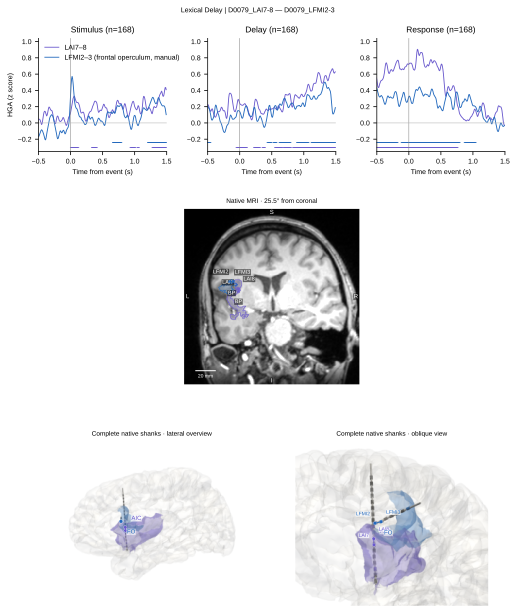

In [28]:
from src.supplementary.operculum_anatomy import COLORS,load_subject,pair_points,localization_review_notes,full_shank_contacts,render_surface,sample_plane,INSULA_NAMES,MRI_PROJECTION_TOL_MM
hga_coronal_exports=[];anatomy_review=[]

def near_coronal_pair_plane(points):
    """Plane through both bipolar midpoints, with the smallest tilt from coronal.

    The normal is the anterior–posterior axis after removing its component along
    the midpoint–midpoint vector, so it stays perpendicular to that vector.
    Horizontal in the slice stays as close as possible to left–right; vertical
    stays superior. Contacts off the plane are projected, not used to tilt it.
    """
    mids=[]
    for region in ('AIC','FO'):
        row=points.loc[points.region.eq(region)&points.role.eq('midpoint')].iloc[0]
        mids.append(row[['x','y','z']].to_numpy(dtype=float))
    span=mids[1]-mids[0];span/=np.linalg.norm(span)
    coronal=np.array([0.,1.,0.])
    normal=coronal-np.dot(coronal,span)*span
    normal/=np.linalg.norm(normal)
    if normal[1]>0:normal=-normal
    superior=np.array([0.,0.,1.])
    axis2=superior-np.dot(superior,normal)*normal
    axis2/=np.linalg.norm(axis2)
    if axis2[2]<0:axis2=-axis2
    right=np.array([1.,0.,0.])
    axis1=right-np.dot(right,normal)*normal
    axis1-=np.dot(axis1,axis2)*axis2
    axis1/=np.linalg.norm(axis1)
    if axis1[0]<0:axis1=-axis1
    origin=np.dot(mids[0],normal)*normal
    tilt=float(np.degrees(np.arccos(np.clip(abs(float(normal[1])),-1.,1.))))
    return origin,axis1,axis2,normal,tilt

def draw_pair_oblique_mri(ax,subject,points):
    """Both pairs on one superior-up MRI. Own contacts and midpoints only."""
    from matplotlib.colors import ListedColormap
    origin,axis1,axis2,normal,tilt=near_coronal_pair_plane(points)
    scale,t1=sample_plane(subject,'mri',origin,axis1,axis2,half=90.,spacing=.5)
    _,atlas=sample_plane(subject,'aparc',origin,axis1,axis2,half=90.,spacing=.5,order=0)
    extent=[scale[0],scale[-1],scale[0],scale[-1]]
    ax.imshow(t1,cmap='gray',origin='lower',extent=extent,
              vmin=subject['mri_limits'][0],vmax=subject['mri_limits'][1],interpolation='none')
    prefix=f'ctx_{subject["hemi"]}_'
    for label_region in ('AIC','FO'):
        if label_region=='AIC':
            codes=[code for code,name in subject['lut'].items()
                   if name.startswith(prefix) and any(n in name for n in INSULA_NAMES)]
        else:
            codes=[code for code,name in subject['lut'].items()
                   if name.startswith(prefix) and 'G_front_inf-Opercular' in name]
        mask=np.isin(atlas,codes)
        if mask.any() and not mask.all():
            ax.imshow(np.ma.masked_where(~mask,np.ones(mask.shape)),
                cmap=ListedColormap([COLORS[label_region]]),origin='lower',extent=extent,
                alpha=.18,interpolation='none',vmin=0,vmax=1)
            ax.contour(scale,scale,mask,levels=[.5],colors=[COLORS[label_region]],linewidths=.65,alpha=.85)
    for region in ('AIC','FO'):
        frame=points.loc[points.region.eq(region)].set_index('role').loc[['contact_1','midpoint','contact_2']].reset_index()
        xyz=frame[['x','y','z']].to_numpy(dtype=float)
        depth=(xyz-origin)@normal
        assert np.max(np.abs(depth))<=MRI_PROJECTION_TOL_MM,(region,np.round(depth,3))
        projected=np.column_stack([(xyz-origin)@axis1,(xyz-origin)@axis2])
        ax.plot(projected[[0,2],0],projected[[0,2],1],c=COLORS[region],lw=.7,zorder=7)
        for i,r in enumerate(frame.itertuples()):
            x,y=projected[i]
            ax.scatter(x,y,s=9 if i==1 else 6,marker='D' if i==1 else 'o',
                       facecolors='none',edgecolors=COLORS[region],linewidths=.6,zorder=8)
            offset=[(-5,8),(0,-13),(5,8)][i]
            ax.annotate('BP' if i==1 else r.contact,(x,y),xytext=offset,
                        ha=['right','center','left'][i],
                        textcoords='offset points',color='white',fontsize=5.5,
                        bbox=dict(facecolor='black',alpha=.55,edgecolor='none',pad=.6))
    ax.plot([-78,-58],[-76,-76],c='white',lw=1)
    ax.text(-68,-83,'20 mm',color='white',ha='center',fontsize=5)
    for axis,positive,negative in [(axis1,(.98,.5),(.02,.5)),(axis2,(.5,.98),(.5,.02))]:
        dominant=int(np.argmax(np.abs(axis)))
        pos=['R','A','S'][dominant];neg=['L','P','I'][dominant]
        if axis[dominant]<0:pos,neg=neg,pos
        for name,where in [(pos,positive),(neg,negative)]:
            ax.text(*where,name,transform=ax.transAxes,color='white',fontsize=6,
                ha='center',va='center',bbox=dict(facecolor='black',alpha=.5,edgecolor='none',pad=.5))
    ax.set_title(f'Native MRI · {tilt:.1f}° from coronal',fontsize=6.5)
    ax.set_xlim(-90,90);ax.set_ylim(-90,90);ax.set_aspect('equal');ax.axis('off')

for receipt in receipts:
    pair_id=receipt['pair_id'];directory=CASE_DIR/'pairs'/pair_id
    info=receipt['pair'];phase_data={p:np.load(directory/f'{p}.npz') for p in ['Stimulus','Delay','Response']}
    for data in phase_data.values():
        assert list(data['conditions'])==['AIC_before','AIC_orthogonal','FO_before','FO_orthogonal']
    native_subject=load_subject(info['subject'],info['hemisphere'])
    native_points=pair_points(info,native_subject)
    review_notes=localization_review_notes(info,native_points)
    anatomy_review.append(dict(pair_id=pair_id,task=info['task'],subject=info['subject'],
        reconstruction=native_subject['recon'],requires_review=bool(review_notes),
        review_reason='; '.join(review_notes),
        current_FO_candidate_midpoint=native_points.loc[native_points.region.eq('FO')&native_points.role.eq('midpoint'),'native_aparc'].iloc[0]))
    shanks=full_shank_contacts(native_subject,native_points)
    channels=((0,ROI_COLORS['Insula'],'LAI7–8',.035),(2,ROI_COLORS['IFG'],'LFMI2–3 (frontal operculum, manual)',.080))
    traces=[np.nanmean(data['zscore'][:,idx,:],axis=0) for data in phase_data.values() for idx,_,_,_ in channels]
    values=np.concatenate(traces)
    low=min(0.,float(np.nanmin(values)));high=max(0.,float(np.nanmax(values)))
    pad=max(.1,(high-low)*.12)
    fig=plt.figure(figsize=(18*cm,22*cm))
    outer=fig.add_gridspec(3,1,height_ratios=(1,1.55,1.45),hspace=.38,left=.07,right=.985,top=.93,bottom=.02)
    top=outer[0].subgridspec(1,3,wspace=.32)
    brain_row=outer[2].subgridspec(1,2,wspace=.06)
    axes=[fig.add_subplot(top[0,0])]
    axes+=[fig.add_subplot(top[0,col],sharex=axes[0],sharey=axes[0]) for col in (1,2)]
    for col,(phase,data) in enumerate(phase_data.items()):
        ax=axes[col];times=data['times']
        for idx,color,label,mark_y in channels:
            ax.plot(times,np.nanmean(data['zscore'][:,idx,:],axis=0),color=color,lw=.9,label=label if col==0 else None)
            sig=np.asarray(data['mask'][idx],dtype=bool)&(data['pvals'][idx]<.05)
            ax.scatter(times[sig],np.full(int(sig.sum()),mark_y),marker='_',s=5,color=color,
                       transform=ax.get_xaxis_transform(),linewidths=.7)
        ax.axvline(0,color='0.5',lw=.5);ax.axhline(0,color='0.7',lw=.5)
        ax.set_xlim(-.5,1.5);ax.set_ylim(low-pad,high+pad)
        ax.spines[['top','right']].set_visible(False)
        ax.set_title(f'{phase} (n={len(data["zscore"])})')
        ax.set_xlabel('Time from event (s)')
    axes[0].set_ylabel('HGA (z score)')
    axes[0].legend(frameon=False,fontsize=7,loc='upper left')
    # One superior-up slice through both midpoints, tilted as little as possible
    # from coronal. Pair contacts and midpoints only; no shaft and no CT.
    # Atlas color stays; Insula / Frontal operculum text is not drawn.
    draw_pair_oblique_mri(fig.add_subplot(outer[1]),native_subject,native_points)
    # Same individual 3D brain as make_pair_figure: both sites, native coordinates,
    # physical shanks and cylindrical contacts. Lateral overview, then oblique view.
    def draw_brain(ax,zoom):
        image,pixels=render_surface(native_subject,native_points,shanks,zoom)
        ax.imshow(image);ax.axis('off')
        for region in ('AIC','FO'):
            inds=np.flatnonzero(native_points.region.eq(region))
            xy=pixels[inds]
            ax.plot(xy[[0,2],0],xy[[0,2],1],c=COLORS[region],lw=.7)
            ax.scatter(xy[[0,2],0],xy[[0,2],1],s=12,marker='o',c=COLORS[region],edgecolors='white',linewidths=.25)
            ax.annotate(region,xy[1],xytext=(6,9 if region=='AIC' else -12),textcoords='offset points',
                color=COLORS[region],fontsize=6,bbox=dict(facecolor='white',alpha=.6,edgecolor='none',pad=.5))
            if zoom:
                for pos,index in ((0,inds[0]),(2,inds[2])):
                    ax.annotate(native_points.iloc[index].contact,pixels[index],
                        xytext=(-5,8) if pos==0 else (5,8),
                        ha='right' if pos==0 else 'left',textcoords='offset points',
                        color=COLORS[region],fontsize=5,
                        bbox=dict(facecolor='white',alpha=.7,edgecolor='none',pad=.3))
        ax.set_title('Complete native shanks · '+('oblique view' if zoom else 'lateral overview'),fontsize=6.5)
    for ax,zoom in zip((fig.add_subplot(brain_row[0,0]),fig.add_subplot(brain_row[0,1])),(False,True)):
        draw_brain(ax,zoom)
    fig.suptitle(f'{TASK_LABELS[info["task"]]} | {info["insula_site"]} — {info["operculum_site"]}',fontsize=7)
    hga_coronal_exports.append(str(save(fig,f'{pair_id}__hga_coronal.svg')))

libEGL warning: pci id for fd 90: 10de:26b2, driver (null)

pci id for fd 107: 10de:26b2, driver (null)
kmsro: driver missing
libEGL warning: egl: failed to create dri2 screen
libEGL warning: pci id for fd 90: 10de:26b2, driver (null)

pci id for fd 107: 10de:26b2, driver (null)
kmsro: driver missing
libEGL warning: egl: failed to create dri2 screen
libEGL warning: failed to open /dev/dri/card8: Permission denied

2026-10-20 14:49:22.447 (2469.326s) [    7FCF6B13C740] vtkEGLRenderWindow.cxx:353   WARN| vtkEGLRenderWindow (0x1308f310): EGL device index: 0 could not be initialized. Trying other devices...
libEGL warning: pci id for fd 90: 10de:26b2, driver (null)

pci id for fd 107: 10de:26b2, driver (null)
kmsro: driver missing
libEGL warning: egl: failed to create dri2 screen
libEGL warning: pci id for fd 90: 10de:26b2, driver (null)

pci id for fd 107: 10de:26b2, driver (null)
kmsro: driver missing
libEGL warning: egl: failed to create dri2 screen
libEGL warning: failed to open /dev/d

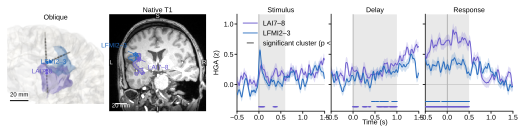

In [29]:
# Publication version of the combined case figure. The preceding cell is left unchanged.
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from src.main_analysis import RESPONSE_WINDOWS
from src.supplementary.operculum_anatomy import (
    COLORS, load_subject, pair_points, full_shank_contacts, render_surface,
    sample_plane, INSULA_NAMES, MRI_PROJECTION_TOL_MM)

# Same windows as RESPONSE_WINDOWS and this case's response_summary.csv.
# The npz mask is the full-epoch cluster mask; there is no window-restricted array.
PHASE_WINDOWS = {'Stimulus': (0.0, 0.6), 'Delay': (0.0, 1.0), 'Response': (-0.5, 0.5)}
assert {phase: RESPONSE_WINDOWS[phase.lower()] for phase in PHASE_WINDOWS} == PHASE_WINDOWS

def near_coronal_pair_plane(points):
    """Plane through both bipolar midpoints, with the smallest tilt from coronal.

    The normal is the anterior–posterior axis after removing its component along
    the midpoint–midpoint vector, so it stays perpendicular to that vector.
    Horizontal in the slice stays as close as possible to left–right; vertical
    stays superior. Contacts off the plane are projected, not used to tilt it.
    """
    mids=[]
    for region in ('AIC','FO'):
        row=points.loc[points.region.eq(region)&points.role.eq('midpoint')].iloc[0]
        mids.append(row[['x','y','z']].to_numpy(dtype=float))
    span=mids[1]-mids[0];span/=np.linalg.norm(span)
    coronal=np.array([0.,1.,0.])
    normal=coronal-np.dot(coronal,span)*span
    normal/=np.linalg.norm(normal)
    if normal[1]>0:normal=-normal
    superior=np.array([0.,0.,1.])
    axis2=superior-np.dot(superior,normal)*normal
    axis2/=np.linalg.norm(axis2)
    if axis2[2]<0:axis2=-axis2
    right=np.array([1.,0.,0.])
    axis1=right-np.dot(right,normal)*normal
    axis1-=np.dot(axis1,axis2)*axis2
    axis1/=np.linalg.norm(axis1)
    if axis1[0]<0:axis1=-axis1
    origin=np.dot(mids[0],normal)*normal
    tilt=float(np.degrees(np.arccos(np.clip(abs(float(normal[1])),-1.,1.))))
    return origin,axis1,axis2,normal,tilt

def trial_mean_sem(trials):
    """Trial mean and SEM. SEM is nanstd (ddof 1) over finite trials / sqrt(n)."""
    count = np.isfinite(trials).sum(axis=0).astype(float)
    mean = np.nanmean(trials, axis=0)
    with np.errstate(invalid='ignore', divide='ignore'):
        sem = np.nanstd(trials, axis=0, ddof=1) / np.sqrt(count)
    sem[count < 2] = np.nan
    return mean, sem

def significant_times(data, idx, times, lo, hi):
    """Cluster samples with p < 0.05 that also fall inside the phase window."""
    cluster = np.asarray(data['mask'][idx], dtype=bool) & (np.asarray(data['pvals'][idx]) < 0.05)
    inside = (times >= lo) & (times < hi)
    for key in ('window_mask', 'significant_in_window'):
        if key in data.files and np.shape(data[key]) == np.shape(data['mask']):
            cluster = cluster & np.asarray(data[key][idx], dtype=bool)
            break
    return cluster & inside

def draw_publication_mri(ax, subject, points):
    """Superior-up T1 through both midpoints. One label per pair."""
    origin, axis1, axis2, normal, tilt = near_coronal_pair_plane(points)
    scale, t1 = sample_plane(subject, 'mri', origin, axis1, axis2, half=90., spacing=.5)
    _, atlas = sample_plane(subject, 'aparc', origin, axis1, axis2, half=90., spacing=.5, order=0)
    extent = [scale[0], scale[-1], scale[0], scale[-1]]
    ax.imshow(t1, cmap='gray', origin='lower', extent=extent,
              vmin=subject['mri_limits'][0], vmax=subject['mri_limits'][1], interpolation='none')
    prefix = f'ctx_{subject["hemi"]}_'
    for label_region in ('AIC', 'FO'):
        if label_region == 'AIC':
            codes = [code for code, name in subject['lut'].items()
                     if name.startswith(prefix) and any(n in name for n in INSULA_NAMES)]
        else:
            codes = [code for code, name in subject['lut'].items()
                     if name.startswith(prefix) and 'G_front_inf-Opercular' in name]
        mask = np.isin(atlas, codes)
        if mask.any() and not mask.all():
            ax.imshow(np.ma.masked_where(~mask, np.ones(mask.shape)),
                      cmap=ListedColormap([COLORS[label_region]]), origin='lower', extent=extent,
                      alpha=.18, interpolation='none', vmin=0, vmax=1)
            ax.contour(scale, scale, mask, levels=[.5], colors=[COLORS[label_region]],
                       linewidths=.65, alpha=.85)
    # Midpoints are 11.3 mm apart; leaders take the names to opposite corners.
    label_offsets = {
        'AIC': (np.array([16., -16.]), 'left', 'center'),
        'FO': (np.array([-16., 16.]), 'right', 'center'),
    }
    pair_names = {'AIC': 'LAI7–8', 'FO': 'LFMI2–3'}
    for region in ('AIC', 'FO'):
        frame = (points.loc[points.region.eq(region)].set_index('role')
                 .loc[['contact_1', 'midpoint', 'contact_2']].reset_index())
        xyz = frame[['x', 'y', 'z']].to_numpy(dtype=float)
        depth = (xyz - origin) @ normal
        assert np.max(np.abs(depth)) <= MRI_PROJECTION_TOL_MM, (region, np.round(depth, 3))
        projected = np.column_stack([(xyz - origin) @ axis1, (xyz - origin) @ axis2])
        ax.plot(projected[[0, 2], 0], projected[[0, 2], 1], c=COLORS[region], lw=.7, zorder=7)
        for i in range(3):
            x, y = projected[i]
            ax.scatter(x, y, s=9 if i == 1 else 6, marker='D' if i == 1 else 'o',
                       facecolors='none', edgecolors=COLORS[region], linewidths=.6, zorder=8)
        offset, ha, va = label_offsets[region]
        ax.annotate(pair_names[region], projected[1], xytext=projected[1] + offset,
                    textcoords='data', ha=ha, va=va, fontsize=6.5, color=COLORS[region],
                    arrowprops=dict(arrowstyle='-', color=COLORS[region], lw=.6),
                    zorder=9)
    ax.plot([-78, -58], [-76, -76], c='white', lw=1)
    ax.text(-68, -83, '20 mm', color='white', ha='center', fontsize=6)
    for axis, positive, negative in [(axis1, (.98, .5), (.02, .5)), (axis2, (.5, .98), (.5, .02))]:
        dominant = int(np.argmax(np.abs(axis)))
        pos, neg = ['R', 'A', 'S'][dominant], ['L', 'P', 'I'][dominant]
        if axis[dominant] < 0:
            pos, neg = neg, pos
        for name, where in ((pos, positive), (neg, negative)):
            ax.text(*where, name, transform=ax.transAxes, color='white', fontsize=6,
                    ha='center', va='center',
                    bbox=dict(facecolor='black', alpha=.5, edgecolor='none', pad=.5))
    ax.set_xlim(-90, 90)
    ax.set_ylim(-90, 90)
    ax.set_aspect('equal')
    ax.axis('off')
    return tilt

def parallel_pixels_per_mm(points, pixels):
    """Image-plane scale of render_surface's parallel projection, in pixels per mm."""
    xyz = points[['x', 'y', 'z']].to_numpy(dtype=float)
    pix = np.asarray(pixels, dtype=float)
    design = np.column_stack([xyz, np.ones(len(xyz))])
    coef, _, rank, _ = np.linalg.lstsq(design, pix, rcond=None)
    assert rank == 4
    residual = float(np.max(np.linalg.norm(design @ coef - pix, axis=1)))
    assert residual < 0.5, residual
    jacobian = coef[:3].T
    singular = np.linalg.svd(jacobian, compute_uv=False)
    assert singular[1] > 0 and abs(singular[0] - singular[1]) / singular[0] < 0.02, singular
    horizontal = np.linalg.lstsq(jacobian, np.array([1.0, 0.0]), rcond=None)[0]
    return 1.0 / float(np.linalg.norm(horizontal))

def draw_mm_bar(ax, image, px_per_mm):
    bar = 20.0 * px_per_mm
    x0, y0 = 28.0, float(image.shape[0]) - 34.0
    assert x0 + bar < image.shape[1] - 16, bar
    ax.plot([x0, x0 + bar], [y0, y0], color='white', lw=2.4, solid_capstyle='butt', zorder=6)
    ax.plot([x0, x0 + bar], [y0, y0], color='black', lw=1.0, solid_capstyle='butt', zorder=7)
    ax.annotate('20 mm', xy=(x0 + bar / 2, y0), xytext=(0, 3), textcoords='offset points',
                ha='center', va='bottom', fontsize=6, color='black',
                bbox=dict(facecolor='white', edgecolor='none', alpha=.85, pad=.2), zorder=7)

def draw_publication_brain(ax, zoom, subject, points, shanks):
    """Full native shanks. Pair names on both views."""
    image, pixels = render_surface(subject, points, shanks, zoom)
    ax.imshow(image)
    ax.axis('off')
    px_per_mm = parallel_pixels_per_mm(points, pixels)
    anchors = {}
    for region, label in (('AIC', 'LAI7–8'), ('FO', 'LFMI2–3')):
        inds = np.flatnonzero(points.region.eq(region))
        xy = pixels[inds]
        ax.plot(xy[[0, 2], 0], xy[[0, 2], 1], c=COLORS[region], lw=.7, zorder=4)
        ax.scatter(xy[[0, 2], 0], xy[[0, 2], 1], s=12, marker='o', c=COLORS[region],
                   edgecolors='white', linewidths=.25, zorder=5)
        anchors[region] = (xy, label, inds)
    aic_mid, fo_mid = anchors['AIC'][0][1], anchors['FO'][0][1]
    delta = fo_mid - aic_mid
    delta = delta / np.linalg.norm(delta)
    perp = np.array([-delta[1], delta[0]])
    for region, sign, along in (('AIC', -1.0, -10.0), ('FO', 1.0, 10.0)):
        xy, label, inds = anchors[region]
        text_at = xy[1] + sign * perp * 48 + delta * along
        text_at = np.clip(text_at, [24, 24], [image.shape[1] - 24, image.shape[0] - 24])
        ax.annotate(label, xy=xy[1], xytext=text_at, textcoords='data',
                    ha='center', va='center', fontsize=6.5, color=COLORS[region],
                    arrowprops=dict(arrowstyle='-', color=COLORS[region], lw=.6),
                    zorder=6)
    draw_mm_bar(ax, image, px_per_mm)
    ax.set_title('Oblique' if zoom else 'Lateral', fontsize=7, pad=2)

for receipt in receipts:
    pair_id = receipt['pair_id']
    directory = CASE_DIR / 'pairs' / pair_id
    info = receipt['pair']
    summary = pd.read_csv(directory / 'response_summary.csv')
    for phase, (lo, hi) in PHASE_WINDOWS.items():
        part = summary.loc[summary.phase.eq(phase)]
        assert np.allclose(part.window_start, lo) and np.allclose(part.window_end, hi)
    phase_data = {phase: np.load(directory / f'{phase}.npz') for phase in PHASE_WINDOWS}
    for data in phase_data.values():
        assert list(data['conditions']) == ['AIC_before', 'AIC_orthogonal', 'FO_before', 'FO_orthogonal']
    native_subject = load_subject(info['subject'], info['hemisphere'])
    native_points = pair_points(info, native_subject)
    origin, _, _, normal, tilt = near_coronal_pair_plane(native_points)
    assert abs(tilt - 25.5) < 0.1
    contact_depth = []
    for region in ('AIC', 'FO'):
        frame = native_points.loc[native_points.region.eq(region) & native_points.role.ne('midpoint')]
        contact_depth.extend((frame[['x', 'y', 'z']].to_numpy(float) - origin) @ normal)
    contact_depth = np.abs(np.asarray(contact_depth, float))
    assert contact_depth.min() > 0.49 and contact_depth.max() < 0.52
    shanks = full_shank_contacts(native_subject, native_points)
    channels = ((0, ROI_COLORS['Insula'], 'LAI7–8'), (2, ROI_COLORS['IFG'], 'LFMI2–3'))
    curves = [trial_mean_sem(data['zscore'][:, idx, :]) for data in phase_data.values() for idx, _, _ in channels]
    stack = np.concatenate([np.concatenate([mean - sem, mean + sem]) for mean, sem in curves])
    stack = stack[np.isfinite(stack)]
    low, high = min(0., float(stack.min())), max(0., float(stack.max()))
    pad = max(.1, (high - low) * .12)

    # Each time axis is 3.8 cm wide. Anatomy squares use that same height,
    # and the bottom margin only clears the tick labels and "Time (s)".
    scale = 18 / 22.10
    hga_cm = 3.8 * scale
    side_cm = 4.2 * scale
    label_cm, gap_hga_cm = 1.12 * scale, 0.28 * scale
    outer_gap_cm = 0.22 * scale
    left_cm, right_cm = 0.10 * scale, 0.08 * scale
    top_cm, bottom_cm = 0.50 * scale, 0.70 * scale
    hga_block_cm = label_cm + 3 * hga_cm + 2 * gap_hga_cm
    fig_w_cm = left_cm + 2 * side_cm + 2 * outer_gap_cm + hga_block_cm + right_cm
    fig_h_cm = top_cm + side_cm + bottom_cm
    fig = plt.figure(figsize=(fig_w_cm * cm, fig_h_cm * cm))
    left, right = left_cm / fig_w_cm, 1 - right_cm / fig_w_cm
    top, bottom = 1 - top_cm / fig_h_cm, bottom_cm / fig_h_cm
    sum_outer = 2 * side_cm + hga_block_cm
    outer_wspace = 3 * outer_gap_cm / sum_outer
    outer = fig.add_gridspec(
        1, 3, width_ratios=(side_cm, side_cm, hga_block_cm), wspace=outer_wspace,
        left=left, right=right, top=top, bottom=bottom)
    brain_ax = fig.add_subplot(outer[0, 0])
    mri_ax = fig.add_subplot(outer[0, 1])
    hga_slot = outer[0, 2].get_position(fig)
    hga_cm = (hga_slot.width * fig_w_cm - label_cm - 2 * gap_hga_cm) / 3
    hga_x = hga_slot.x0 * fig_w_cm + label_cm
    axes = []
    for col in range(3):
        rect = [hga_x / fig_w_cm, hga_slot.y0, hga_cm / fig_w_cm, hga_slot.height]
        axes.append(fig.add_axes(rect, sharex=axes[0] if col else None, sharey=axes[0] if col else None))
        hga_x += hga_cm + gap_hga_cm
    for col, (phase, data) in enumerate(phase_data.items()):
        ax = axes[col]
        times = np.asarray(data['times'], float)
        lo, hi = PHASE_WINDOWS[phase]
        ax.axvspan(lo, hi, facecolor='0.45', alpha=0.16, lw=0, zorder=0)
        for (idx, color, label), ymark in zip(channels, (0.045, 0.10)):
            mean, sem = trial_mean_sem(data['zscore'][:, idx, :])
            ax.fill_between(times, mean - sem, mean + sem, color=color, alpha=0.2,
                            linewidth=0, zorder=2)
            ax.plot(times, mean, color=color, lw=.9, zorder=3, label=label if col == 0 else None)
            sig = significant_times(data, idx, times, lo, hi)
            ax.scatter(times[sig], np.full(int(sig.sum()), ymark), marker='_', s=5, color=color,
                       transform=ax.get_xaxis_transform(), linewidths=.7, zorder=4)
        ax.axvline(0, color='0.5', lw=.5, zorder=1)
        ax.axhline(0, color='0.7', lw=.5, zorder=1)
        ax.set_xlim(-.5, 1.5)
        ax.set_ylim(low - pad, high + pad)
        ax.spines[['top', 'right']].set_visible(False)
        ax.set_title(phase, fontsize=7, pad=2)
        ax.tick_params(axis='both', labelsize=7, length=2.5, pad=1)
        if col:
            ax.tick_params(labelleft=False)
    axes[0].set_ylabel('HGA (z)', fontsize=7)
    sig_proxy = Line2D([], [], color='0.15', marker='_', linestyle='None', markersize=7, markeredgewidth=.8)
    handles, labels = axes[0].get_legend_handles_labels()
    axes[0].legend(handles + [sig_proxy], labels + ['significant cluster (p < 0.05)'],
                   frameon=False, fontsize=7, loc='upper left')
    draw_publication_brain(brain_ax, zoom=True, subject=native_subject, points=native_points, shanks=shanks)
    drawn_tilt = draw_publication_mri(mri_ax, native_subject, native_points)
    assert abs(drawn_tilt - tilt) < 1e-9
    mri_ax.set_title('Native T1', fontsize=7, pad=2)
    fig.text((axes[0].get_position().x0 + axes[2].get_position().x1) / 2,
             0.17 / fig_h_cm, 'Time (s)', ha='center', va='center', fontsize=7)
    save(fig, f'{pair_id}__hga_coronal_pub.svg')


### Publication caption

One participant (D0079, left, Lexical Delay, Repeat+sound). This illustration is separate from the automatic LFMI7–8 control. Traces are the trial-mean high-gamma before orthogonalization, and the shading is the trial-wise SEM at that electrode. Underscores mark 5000-permutation clusters (p < 0.05) restricted to the phase windows Stimulus [0, 0.6), Delay [0, 1), and Response [−0.5, 0.5). The anatomical panel is one superior-up native T1 through both midpoints, 25.5° from coronal, with the four contacts projected by 0.50–0.51 mm. In-plane letters are the dominant in-plane directions, not a cardinal coronal. LAI7–8 is designated anterior insular cortex (Destrieux midpoint: superior circular sulcus of the insula) and LFMI2–3 is designated frontal operculum (Destrieux midpoint: cerebral white matter). Orthogonalization, shown separately, keeps signal not explained by the neighbor's instantaneous in-phase component and does not demonstrate independent generators.


In [30]:
results=pd.read_csv(CASE_DIR/'pairs'/pair_id/'response_summary.csv')
results.to_csv(DATA_DIR/'response_summary.csv',index=False)
display(results[['phase','condition','n_trials','mean_response_z','baseline_subtracted_response_uv','significant_in_window']])
for p,h in audit['protected_inputs'].items():
    assert hashlib.sha256(Path(p).read_bytes()).hexdigest()==h
for p,source in receipts[0]['sources'].items():
    assert hashlib.sha256(Path(p).read_bytes()).hexdigest()==source['sha256']
pd.DataFrame(anatomy_review).rename(columns={'requires_review':'atlas_disagrees_with_manual_localization','review_reason':'original_atlas_discrepancy'}).to_csv(DATA_DIR/'atlas_discrepancies.csv',index=False)
manifest=dict(case=case,source_case_audit=str(CASE_DIR/'case_audit.json'),
    signal_receipt=str(CASE_DIR/'pairs'/pair_id/'completed.json'),
    original_plot_source='vizpub/supplementary/operculum.ipynb',
    plot_changes='Combined __hga_coronal.svg: before-orthogonalization HGA with both sites in each phase panel, one native MRI slice through both bipolar midpoints (minimal tilt from coronal, pair contacts only, no Insula/Frontal operculum text), and the individual native 3D brain (lateral overview and oblique shank view)',
    inference='Original per-branch/phase time_perm_cluster, 5000 permutations; descriptive selected example, no pooled group inference',
    hga_coronal_exports=hga_coronal_exports,
    main_figures_NMF_and_automatic_controls_unchanged=True)
(DATA_DIR/'analysis_manifest.json').write_text(json.dumps(manifest,indent=2)+'\n')


,phase,condition,n_trials,mean_response_z,baseline_subtracted_response_uv,significant_in_window
0,Stimulus,AIC_before,168,0.178720,0.251026,True
1,Stimulus,AIC_orthogonal,168,0.088569,0.107071,False
2,Stimulus,FO_before,168,0.096707,0.118849,False
3,Stimulus,FO_orthogonal,168,0.033717,0.033634,False
4,Delay,AIC_before,168,0.215958,0.303330,True
5,Delay,AIC_orthogonal,168,0.125626,0.151869,True
6,Delay,FO_before,168,0.153546,0.188701,True
7,Delay,FO_orthogonal,168,0.099259,0.099017,True
8,Response,AIC_before,168,0.692630,0.972852,True
9,Response,AIC_orthogonal,168,0.475213,0.574487,True


1895